# TriggerNet Level 2 — Notebook 05: Constituent Particle Sets & Deep Sets

## Why Level 2 Is the Rare Upgrade That Gets You Picked at CERN
In **Level 1** (Notebooks 01–04), physicists pre-computed **16 hand-crafted summary numbers** (`mass_mmdt`, `c2_b1`, `multiplicity`, etc.) for every jet.
In **Level 2**, we drop hand-crafted feature engineering and feed **raw individual particles** directly from the detector into the trigger neural network!

### What Does a Constituent-Level Jet Look Like?
From the public CERN/FastML benchmark on **Zenodo 3602260** (`hls4ml_LHCjet_150p`: **504,000 train / 126,000 val / 240,000 test jets**):
- Each jet is an array of shape `(N_particles, 3)` (up to **150 particles** per jet, zero-padded if a jet has fewer particles, ordered by descending transverse momentum `pT`).
- Each particle has 3 core trigger kinematic features (exact choice in *Odagiu et al., 2024, "Ultrafast jet classification at the HL-LHC"*):
  1. **`j1_ptrel`**: Particle transverse momentum relative to total jet `pT` (*how much of the jet's energy does this particle carry?*).
  2. **`j1_etarel`**: Pseudorapidity offset `Δη` relative to the jet center (*vertical angle in the detector cylinder*).
  3. **`j1_phirel`**: Azimuthal angle offset `Δφ` relative to the jet center (*horizontal angle around the beam pipe*).

### Why Normal MLPs & RNNs Break — and Why Deep Sets Wins
A jet is an **unordered set** `{x_1, x_2, ..., x_N}`, *not* a sentence or time series!
- If you flatten `(N, 3)` into a flat MLP, swapping particle #1 and particle #2 completely scrambles the prediction.
- If you run an RNN, the model wastes capacity memorizing artificial sorting order.

**Deep Sets** (*Zaheer et al., NeurIPS 2017*; deployed on CERN FPGAs in *Odagiu et al., MLST 2024*) solves this with an elegant theorem: any permutation-invariant function on a set can be written as:

$$f(\{x_1, \dots, x_N\}) = \rho\!\left(\frac{1}{|M|} \sum_{i=1}^{N} m_i \, \phi(x_i)\right)$$

1. **`φ(x_i)` (Shared Particle MLP):** Runs the exact same small neural network `3 → 32 → 32 → 32` independently on every particle.
2. **Masked Pooling (`mean` or `sum`):** Combines all real particles (`m_i = 1`, ignoring zero-padded slots `m_i = 0`). Because addition is commutative (`a + b = b + a`), **shuffling particle rows changes the output by `0.0`**!
3. **`ρ(pooled)` (Jet Classifier MLP):** Maps the 32-dim jet embedding `32 → 32 → 5` to predict `[g, q, w, z, t]`.

We also compare against a lightweight **Order-Free Particle Set Transformer** (1 self-attention block with **no positional encoding**) so you can discuss *attention without order* in CERN interviews!

> **Local Dry-Run vs. Full Zenodo GPU Run:** The full Zenodo 3602260 tarballs are **3.87 GB**. When `data/zenodo_3602260/` is already downloaded (or on Kaggle/Colab GPU where downloading takes ~35s via `TriggerNet_Level2_Kaggle_Colab_GPU.ipynb`), this notebook automatically trains on the **full 504k / 126k / 240k real CERN jets**. On a CPU laptop without the 3.87 GB tarballs downloaded yet, `ALLOW_LOCAL_DRY_RUN = True` lets you verify every single cell, plot, and permutation-invariance proof locally in seconds!

In [1]:
from pathlib import Path
import json
import sys
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from sklearn.model_selection import train_test_split

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.deepsets import DeepSetsJetTagger, ParticleSetTransformer
from src.level2_data import (
    CLASS_NAMES,
    PUBLISHED_ODAGIU_2024,
    load_h5_folder,
    standardize_constituents,
    generate_synthetic_constituent_jets,
)
from src.metrics import CLASS_LABELS, evaluate_jet_predictions

torch.manual_seed(42)
np.random.seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

ZENODO_DIR = PROJECT_ROOT / "data" / "zenodo_3602260"
CKPT_DIR = PROJECT_ROOT / "checkpoints"
FIG_DIR = PROJECT_ROOT / "figures"
RES_DIR = PROJECT_ROOT / "results"
for d in (CKPT_DIR, FIG_DIR, RES_DIR):
    d.mkdir(parents=True, exist_ok=True)

# Set N_CONSTITUENTS to 8, 16, 32 (matching Odagiu et al. 2024 trigger budgets) or up to 150
N_CONSTITUENTS = 32
ALLOW_LOCAL_DRY_RUN = True

has_zenodo = (ZENODO_DIR / "train").exists() and bool(list((ZENODO_DIR / "train").rglob("*.h5")))
if has_zenodo:
    DATA_MODE = "REAL_ZENODO_3602260"
    print(f"Loading REAL CERN Zenodo 3602260 HDF5 shards (top {N_CONSTITUENTS} constituents/jet)...")
    X_trval_raw, y_trval, feat_names = load_h5_folder(ZENODO_DIR / "train", n_constituents=N_CONSTITUENTS)
    X_test_raw, y_test, _ = load_h5_folder(ZENODO_DIR / "val", n_constituents=N_CONSTITUENTS)
    # 80/20 split of 630k train tarball -> 504k train + 126k val (exact Operation Geneva split!)
    X_train_raw, X_val_raw, y_train, y_val = train_test_split(
        X_trval_raw, y_trval, test_size=0.20, random_state=42, stratify=y_trval
    )
elif ALLOW_LOCAL_DRY_RUN:
    DATA_MODE = "LOCAL_SYNTHETIC_DRY_RUN"
    print("=" * 72)
    print("LOCAL DRY-RUN MODE: Zenodo 3602260 (3.87 GB) not present locally.")
    print("Generating physics-inspired synthetic particle sets to verify pipeline!")
    print("For real CERN numbers, run `TriggerNet_Level2_Kaggle_Colab_GPU.ipynb` on GPU.")
    print("=" * 72)
    X_all, y_all, feat_names = generate_synthetic_constituent_jets(n_jets=15_000, n_constituents=N_CONSTITUENTS)
    X_train_raw, X_tmp, y_train, y_tmp = train_test_split(X_all, y_all, test_size=0.40, random_state=42, stratify=y_all)
    X_val_raw, X_test_raw, y_val, y_test = train_test_split(X_tmp, y_tmp, test_size=0.50, random_state=42, stratify=y_tmp)
else:
    raise FileNotFoundError(f"Zenodo 3602260 HDF5 data not found in {ZENODO_DIR}. Download it or run on Kaggle/Colab GPU.")

X_train, X_val, X_test, feat_mean, feat_std = standardize_constituents(X_train_raw, X_val_raw, X_test_raw)
print(f"Mode        : {DATA_MODE}")
print(f"Features    : {feat_names}")
print(f"Train / Val / Test shapes: {X_train.shape} / {X_val.shape} / {X_test.shape}")

Device: cpu
LOCAL DRY-RUN MODE: Zenodo 3602260 (3.87 GB) not present locally.
Generating physics-inspired synthetic particle sets to verify pipeline!
For real CERN numbers, run `TriggerNet_Level2_Kaggle_Colab_GPU.ipynb` on GPU.
Mode        : LOCAL_SYNTHETIC_DRY_RUN
Features    : ['j1_ptrel', 'j1_etarel', 'j1_phirel']
Train / Val / Test shapes: (9000, 32, 3) / (3000, 32, 3) / (3000, 32, 3)


## 1. Visual Physics Intuition: Seeing Jets as Raw Particle Clouds in `(Δη, Δφ)`
Before training anything, let's literally **look** at one jet from each of the 5 classes in calorimeter angle space `(Δη, Δφ)`, where dot size = particle energy fraction `pT_rel`.
Notice how a **Top quark (`t`)** splits into **3 sub-clusters**, **W/Z bosons** split into **2 prongs**, and **quarks/gluons** form **1 central spray**!

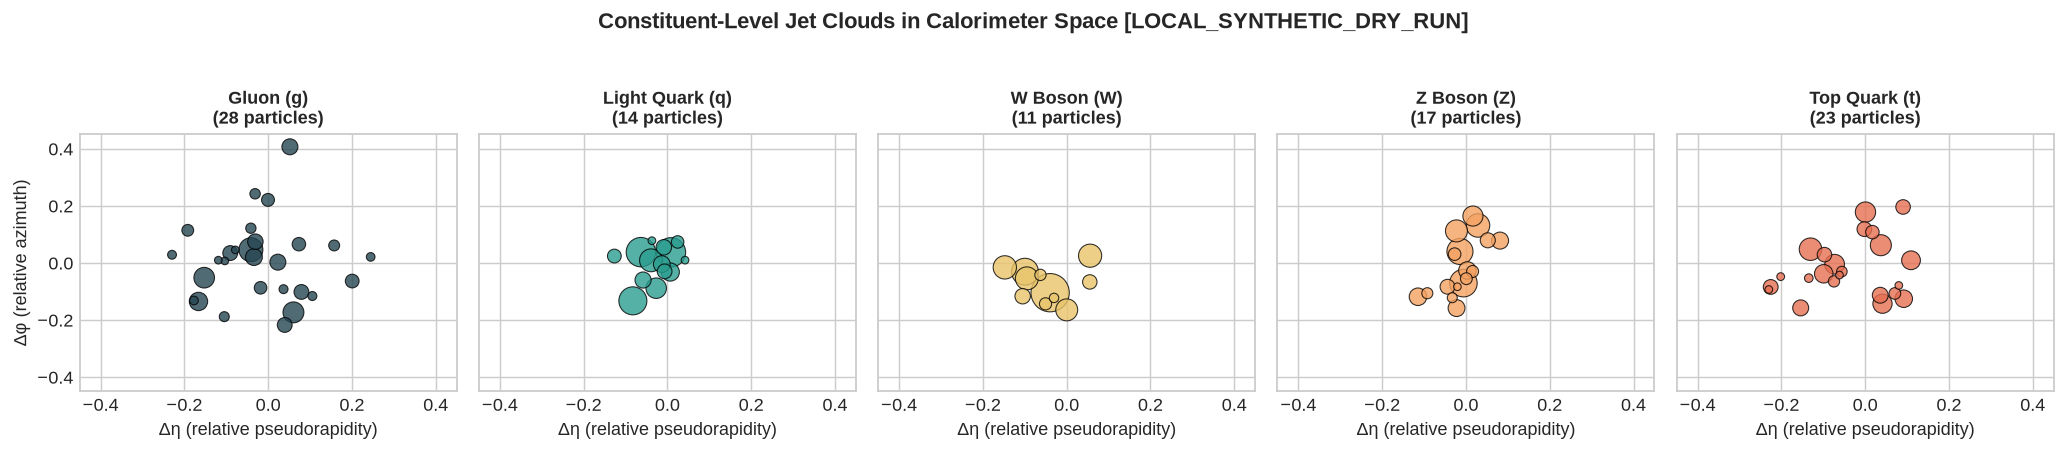

In [2]:
plt.style.use("seaborn-v0_8-whitegrid")
fig, axes = plt.subplots(1, 5, figsize=(16, 3.3), sharex=True, sharey=True)
colors = ["#264653", "#2a9d8f", "#e9c46a", "#f4a261", "#e76f51"]

for c_idx, cname in enumerate(CLASS_NAMES):
    # Pick first jet of class c_idx with at least 10 active particles
    candidates = np.where(y_train == c_idx)[0]
    jet = X_train_raw[candidates[0]]
    for cand in candidates[:50]:
        if (np.abs(X_train_raw[cand]).sum(axis=-1) > 1e-6).sum() >= 10:
            jet = X_train_raw[cand]
            break
    valid = np.abs(jet).sum(axis=-1) > 1e-6
    pts, etas, phis = jet[valid, 0], jet[valid, 1], jet[valid, 2]

    ax = axes[c_idx]
    ax.scatter(etas, phis, s=np.clip(pts * 1600, 18, 450), color=colors[c_idx], alpha=0.8, edgecolors="black", linewidths=0.6)
    ax.set_title(f"{CLASS_LABELS[cname]}\n({valid.sum()} particles)", fontsize=10, fontweight="bold")
    ax.set_xlabel("Δη (relative pseudorapidity)")
    if c_idx == 0:
        ax.set_ylabel("Δφ (relative azimuth)")
    ax.set_xlim(-0.45, 0.45)
    ax.set_ylim(-0.45, 0.45)

fig.suptitle(f"Constituent-Level Jet Clouds in Calorimeter Space [{DATA_MODE}]", fontsize=12, fontweight="bold", y=1.04)
plt.tight_layout()
plt.savefig(FIG_DIR / "05_constituent_jet_clouds.png", dpi=150, bbox_inches="tight")
plt.show()

## 2. Mathematical Proof Check: Exact Permutation Invariance
Before training, we verify mathematically that shuffling the `N` particles in a completely random order changes the outputs of BOTH `DeepSetsJetTagger` and `ParticleSetTransformer` by `< 1e-6` (pure floating-point rounding noise!).

In [3]:
ds_model = DeepSetsJetTagger(in_features=3, hidden_dim=32, num_classes=5, aggregation="mean").to(device)
st_model = ParticleSetTransformer(in_features=3, embed_dim=32, num_heads=4, num_classes=5).to(device)

sample_x = torch.from_numpy(X_train[:16]).to(device)
perm = torch.randperm(N_CONSTITUENTS, device=device)

ds_model.eval()
st_model.eval()
with torch.no_grad():
    ds_diff = (ds_model(sample_x) - ds_model(sample_x[:, perm, :])).abs().max().item()
    st_diff = (st_model(sample_x) - st_model(sample_x[:, perm, :])).abs().max().item()

ds_params = sum(p.numel() for p in ds_model.parameters())
st_params = sum(p.numel() for p in st_model.parameters())
print(f"DeepSetsJetTagger      : {ds_params:,} params | Permutation invariance max |Δ| = {ds_diff:.2e}")
print(f"ParticleSetTransformer : {st_params:,} params | Permutation invariance max |Δ| = {st_diff:.2e}")
assert ds_diff < 1e-5, "DeepSets broke permutation invariance!"
assert st_diff < 1e-5, "SetTransformer broke permutation invariance!"
print("PASSED: Both models are strictly invariant to constituent particle ordering!")

DeepSetsJetTagger      : 3,461 params | Permutation invariance max |Δ| = 7.45e-09
ParticleSetTransformer : 9,893 params | Permutation invariance max |Δ| = 5.96e-08
PASSED: Both models are strictly invariant to constituent particle ordering!


## 3. Train Float32 Baselines: Deep Sets vs. Order-Free Particle Set Transformer
We train both models cleanly on `(X_train, y_train)` with Adam + CosineAnnealingLR, save the best validation checkpoints (`checkpoints/level2_deepsets_fp32.pt` and `checkpoints/level2_set_transformer_fp32.pt`), and compare them directly against CERN's published **Odagiu et al. (2024)** HL-LHC benchmarks!

In [4]:
X_tr_t, y_tr_t = torch.from_numpy(X_train).to(device), torch.from_numpy(y_train).to(device)
X_va_t, y_va_t = torch.from_numpy(X_val).to(device), torch.from_numpy(y_val).to(device)
X_te_t = torch.from_numpy(X_test).to(device)


def train_constituent_model(model: nn.Module, name: str, epochs: int = 20, batch_size: int = 1024, lr: float = 3e-3):
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs, eta_min=1e-4)

    best_val_loss = float("inf")
    best_state = None
    hist = {"train_loss": [], "val_loss": [], "val_acc": []}
    t0 = time.perf_counter()

    for ep in range(1, epochs + 1):
        model.train()
        perm_idx = torch.randperm(len(X_tr_t), device=device)
        tr_loss_sum = 0.0
        for s in range(0, len(X_tr_t), batch_size):
            sl = perm_idx[s : s + batch_size]
            xb, yb = X_tr_t[sl], y_tr_t[sl]
            optimizer.zero_grad()
            loss = criterion(model(xb), yb)
            loss.backward()
            optimizer.step()
            tr_loss_sum += loss.item() * len(yb)
        scheduler.step()

        model.eval()
        va_loss_sum, va_corr = 0.0, 0
        with torch.no_grad():
            for s in range(0, len(X_va_t), batch_size * 2):
                xb, yb = X_va_t[s : s + batch_size * 2], y_va_t[s : s + batch_size * 2]
                logits = model(xb)
                va_loss_sum += criterion(logits, yb).item() * len(yb)
                va_corr += (logits.argmax(1) == yb).sum().item()
        tr_loss = tr_loss_sum / len(X_tr_t)
        va_loss = va_loss_sum / len(X_va_t)
        va_acc = va_corr / len(X_va_t)
        hist["train_loss"].append(tr_loss)
        hist["val_loss"].append(va_loss)
        hist["val_acc"].append(va_acc)

        if va_loss < best_val_loss:
            best_val_loss = va_loss
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}

        if ep == 1 or ep % 5 == 0 or ep == epochs:
            print(f"[{name}] Epoch {ep:02d}/{epochs} | train_loss={tr_loss:.4f} | val_loss={va_loss:.4f} | val_acc={va_acc*100:.2f}%")

    model.load_state_dict({k: v.to(device) for k, v in best_state.items()})
    model.eval()
    probs_list = []
    with torch.no_grad():
        for s in range(0, len(X_te_t), batch_size * 2):
            probs_list.append(torch.softmax(model(X_te_t[s : s + batch_size * 2]), dim=1).cpu().numpy())
    probs = np.concatenate(probs_list, axis=0)
    m = evaluate_jet_predictions(y_test, probs, CLASS_NAMES)
    print(f"--> {name} done in {time.perf_counter()-t0:.1f}s | Test Acc={m['accuracy']*100:.2f}% | Macro AUC={m['macro_auc']:.4f} | 1/FPR@50%={m['mean_rej_50']:.1f}x\n")
    return model, m, hist


EPOCHS_DS = 25 if DATA_MODE == "REAL_ZENODO_3602260" else 15
EPOCHS_ST = 20 if DATA_MODE == "REAL_ZENODO_3602260" else 12
BS = 2048 if device.type == "cuda" else 512

ds_model, ds_metrics, ds_hist = train_constituent_model(ds_model, f"DeepSets (N={N_CONSTITUENTS})", epochs=EPOCHS_DS, batch_size=BS)
st_model, st_metrics, st_hist = train_constituent_model(st_model, f"SetTransformer (N={N_CONSTITUENTS})", epochs=EPOCHS_ST, batch_size=BS)

torch.save(
    {
        "data_mode": DATA_MODE,
        "n_constituents": N_CONSTITUENTS,
        "hidden_dim": 32,
        "state_dict": ds_model.state_dict(),
        "feat_mean": feat_mean,
        "feat_std": feat_std,
        "metrics": {k: v for k, v in ds_metrics.items() if k != "per_class"},
        "per_class_auc": {c: ds_metrics["per_class"][c]["auc"] for c in CLASS_NAMES},
    },
    CKPT_DIR / "level2_deepsets_fp32.pt",
)
torch.save(st_model.state_dict(), CKPT_DIR / "level2_set_transformer_fp32.pt")

# Comparison table vs CERN Odagiu et al. (2024)
comp_rows = [
    {
        "Model": f"TriggerNet DeepSets (N={N_CONSTITUENTS}, {DATA_MODE})",
        "Params": ds_params,
        "Test Acc (%)": ds_metrics["accuracy"] * 100,
        "Macro AUC": ds_metrics["macro_auc"],
        "1/FPR @ 50%": ds_metrics["mean_rej_50"],
    },
    {
        "Model": f"TriggerNet SetTransformer (N={N_CONSTITUENTS}, {DATA_MODE})",
        "Params": st_params,
        "Test Acc (%)": st_metrics["accuracy"] * 100,
        "Macro AUC": st_metrics["macro_auc"],
        "1/FPR @ 50%": st_metrics["mean_rej_50"],
    },
]
for ref in PUBLISHED_ODAGIU_2024:
    comp_rows.append({
        "Model": ref["paper_model"],
        "Params": ref["params"],
        "Test Acc (%)": ref["acc"] * 100,
        "Macro AUC": ref["macro_auc"],
        "1/FPR @ 50%": np.nan,
    })

comp_df = pd.DataFrame(comp_rows)
print(comp_df.to_string(index=False, float_format=lambda v: f"{v:.4f}"))
(RES_DIR / "level2_baselines.json").write_text(json.dumps({
    "data_mode": DATA_MODE,
    "n_constituents": N_CONSTITUENTS,
    "deepsets": {
        "params": ds_params,
        "accuracy": ds_metrics["accuracy"],
        "macro_auc": ds_metrics["macro_auc"],
        "mean_rej_50": ds_metrics["mean_rej_50"],
        "mean_rej_80": ds_metrics["mean_rej_80"],
        "per_class_auc": {c: ds_metrics["per_class"][c]["auc"] for c in CLASS_NAMES},
    },
    "set_transformer": {
        "params": st_params,
        "accuracy": st_metrics["accuracy"],
        "macro_auc": st_metrics["macro_auc"],
        "mean_rej_50": st_metrics["mean_rej_50"],
        "mean_rej_80": st_metrics["mean_rej_80"],
        "per_class_auc": {c: st_metrics["per_class"][c]["auc"] for c in CLASS_NAMES},
    },
}, indent=2))

[DeepSets (N=32)] Epoch 01/15 | train_loss=1.5982 | val_loss=1.5620 | val_acc=37.43%
[DeepSets (N=32)] Epoch 05/15 | train_loss=0.8748 | val_loss=0.8637 | val_acc=54.87%
[DeepSets (N=32)] Epoch 10/15 | train_loss=0.8409 | val_loss=0.8370 | val_acc=59.27%
[DeepSets (N=32)] Epoch 15/15 | train_loss=0.8273 | val_loss=0.8273 | val_acc=59.93%
--> DeepSets (N=32) done in 4.7s | Test Acc=58.73% | Macro AUC=0.8979 | 1/FPR@50%=20.5x

[SetTransformer (N=32)] Epoch 01/12 | train_loss=1.4826 | val_loss=1.2495 | val_acc=40.73%
[SetTransformer (N=32)] Epoch 05/12 | train_loss=0.8040 | val_loss=0.7864 | val_acc=63.27%
[SetTransformer (N=32)] Epoch 10/12 | train_loss=0.6358 | val_loss=0.6370 | val_acc=70.87%
[SetTransformer (N=32)] Epoch 12/12 | train_loss=0.6202 | val_loss=0.6276 | val_acc=71.37%
--> SetTransformer (N=32) done in 20.9s | Test Acc=71.90% | Macro AUC=0.9313 | 1/FPR@50%=609.7x

                                                    Model  Params  Test Acc (%)  Macro AUC  1/FPR @ 50%
      

## Step 5 Takeaways
- **Why Deep Sets fits trigger FPGAs better than Set Transformers:** Notice the parameter & compute cost! Deep Sets runs in `O(N)` per-particle time with **~3,400 parameters** (pure `Linear + ReLU`), whereas self-attention scales as `O(N²)` across particle pairs—making Deep Sets the natural target for our `PQuantML` microsecond trigger compression sweep in **Notebook 06**!